# Tugas 4: Klasifikasi Machine Learning
## Prediksi Jenis Bencana: BANJIR vs TANAH LONGSOR

**Mata kuliah:** Pengantar Sains Data, Matana University

**Anggota Kelompok:**
1. Faridz Henry Saaba
2. Ridwan Hamadi Alif
3. Satria Ramadhani

### **Latar Belakang dan Tujuan**
Banjir dan tanah longsor adalah dua jenis bencana yang paling sering tercatat di Indonesia, dan keduanya menumpuk di musim hujan. Dugaan awal kami: keduanya meninggalkan jejak dampak yang berbeda. Banjir identik dengan rumah terendam, longsor identik dengan rumah rusak.

**Pertanyaan utama:** seberapa baik catatan dampak suatu kejadian (korban, rumah, fasilitas) dan bulan kejadian bisa membedakan banjir dari tanah longsor?

**Tujuan:**
1. Memeriksa dan membersihkan data kejadian bencana.
2. Membangun model Gaussian Naive Bayes dan Logistic Regression.
3. Memvalidasi model dengan metrik, confusion matrix, cross validation, dan ROC-AUC.
4. Menginterpretasikan hasil dan membandingkan kedua model.

### **Tabel Variabel**
| Kolom | Keterangan | Dipakai? |
| :--- | :--- | :--- |
| `city_id` | ID kabupaten/kota | Tidak (hanya nomor, bukan bukti) |
| `date` | Tanggal kejadian | Diekstrak menjadi `month` |
| `disaster_type` | Jenis bencana | Target (difilter 2 kelas) |
| `city`, `province` | Lokasi | Tidak (terlalu banyak kategori) |
| `cause` | Teks penyebab | Tidak (teks bebas, tidak terstandar) |
| `death`, `missing_person`, `injured_person` | Jumlah korban | Fitur |
| `damaged_house`, `damaged_facility` | Kerusakan | Fitur |
| `flooded_house` | Rumah terendam | Hanya skenario B (alasannya di Bagian 4) |

**Ruang lingkup:** data ini adalah catatan kejadian. Semua temuan menunjukkan **asosiasi**, bukan sebab-akibat.

## 1. Import Library dan Persiapan Data

Data awal memuat 13 jenis bencana dengan jumlah yang sangat timpang. Mengklasifikasikan semuanya sekaligus tidak sehat, jadi kami memilih dua jenis terbesar yang cukup berimbang: banjir dan tanah longsor. Target dibuat biner: `0` = BANJIR, `1` = TANAH LONGSOR.

In [1]:
# Cell 1: import library, muat data, filter dua kelas, buat target
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('../data_raw/data_bencana.xlsx')

print("Jenis bencana pada data awal:")
print(df['disaster_type'].value_counts())

# Ambil hanya dua jenis bencana (klasifikasi biner)
df_filtered = df[df['disaster_type'].isin(['BANJIR', 'TANAH LONGSOR'])].copy()

# Target: 0 = BANJIR, 1 = TANAH LONGSOR
df_filtered['target'] = df_filtered['disaster_type'].map({'BANJIR': 0, 'TANAH LONGSOR': 1})

print(f"\nData awal      : {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Setelah filter : {df_filtered.shape[0]} baris")
print("\nDistribusi target (0 = BANJIR, 1 = TANAH LONGSOR):")
print(df_filtered['target'].value_counts())
df_filtered.head()

Jenis bencana pada data awal:
disaster_type
BANJIR                         8605
CUACA EKSTREM                  7268
TANAH LONGSOR                  5585
KEBAKARAN HUTAN DAN LAHAN      4967
PUTING BELIUNG                 1113
KEKERINGAN                      489
GEMPA BUMI                      370
GELOMBANG PASANG / ABRASI       270
ERUPSI GUNUNG API                90
TSUNAMI                           7
GEMPA BUMI DAN TSUNAMI            5
GELOMBANG PASANG DAN ABRASI       3
LETUSAN GUNUNG API                1
Name: count, dtype: int64

Data awal      : 28773 baris, 12 kolom
Setelah filter : 14190 baris

Distribusi target (0 = BANJIR, 1 = TANAH LONGSOR):
target
0    8605
1    5585
Name: count, dtype: int64


,city_id,date,disaster_type,city,province,cause,death,missing_person,injured_person,damaged_house,flooded_house,damaged_facility,target
0,5310,2018-01-01,BANJIR,MANGGARAI,NUSA TENGGARA TIMUR,Tidak diketahui,0.0,0.0,0.0,1.0,0.0,0,0
1,6311,2018-01-01,BANJIR,BALANGAN,KALIMANTAN SELATAN,Tidak diketahui,0.0,0.0,0.0,0.0,25.0,0,0
2,5103,2018-01-01,BANJIR,BADUNG,BALI,Tidak diketahui,0.0,0.0,0.0,0.0,3.0,0,0
3,5106,2018-01-01,TANAH LONGSOR,BANGLI,BALI,Tidak diketahui,0.0,0.0,0.0,1.0,0.0,0,1
4,5310,2018-01-01,TANAH LONGSOR,MANGGARAI,NUSA TENGGARA TIMUR,Tidak diketahui,0.0,0.0,0.0,1.0,0.0,0,1


**Insight:**
- Dari 28.773 kejadian, tersisa 14.190 kejadian banjir dan tanah longsor.
- Proporsinya sekitar 60,6% banjir dan 39,4% longsor. Rasio ini wajar dan tidak butuh teknik penanganan imbalance. Nanti `stratify=y` menjaga proporsi ini di data latih dan uji.

## 2. Pemeriksaan Kualitas Data

Tiga pemeriksaan awal: statistik deskriptif, nilai kosong, dan duplikat. Kolom jumlah biasanya miring ke kanan, jadi ringkasan angkanya perlu dibaca teliti, bukan sekadar dilihat rata-ratanya.

In [2]:
# Cell 2: statistik deskriptif, missing values, duplikat
from IPython.display import display

kolom_angka = ['death', 'missing_person', 'injured_person',
               'damaged_house', 'flooded_house', 'damaged_facility']

ringkas = df_filtered[kolom_angka].describe().T.round(3)
ringkas['persen_nol'] = ((df_filtered[kolom_angka] == 0).mean() * 100).round(1)
print("--- Statistik deskriptif + persentase nilai nol ---")
display(ringkas)

print("\nJumlah sel kosong:", df_filtered.isnull().sum().sum())
print("Jumlah baris duplikat:", df_filtered.duplicated().sum())

--- Statistik deskriptif + persentase nilai nol ---


,count,mean,std,min,25%,50%,75%,max,persen_nol
death,14190.0,0.244,1.637,0.0,0.0,0.0,0.258,105.0,57.6
missing_person,14190.0,0.041,0.761,0.0,0.0,0.0,0.054,82.0,60.1
injured_person,14190.0,1.212,31.852,0.0,0.0,0.0,1.723,3151.0,58.2
damaged_house,14190.0,15.952,302.347,0.0,0.0,0.0,1.000,19812.0,58.5
flooded_house,14190.0,441.301,2291.050,0.0,0.0,3.0,161.000,104114.0,48.2
damaged_facility,14190.0,1.181,24.667,0.0,0.0,0.0,0.000,2037.0,85.8



Jumlah sel kosong: 0
Jumlah baris duplikat: 144


**Insight:**
- Persentase nol sangat tinggi dan nilai maksimum jauh di atas kuartil ke-75. Distribusi seperti ini miring ke kanan dan jauh dari normal, jadi nanti perlu transformasi sebelum pemodelan.
- Ada yang janggal: kuartil kolom `death` dan `injured_person` bernilai pecahan. Jumlah orang tidak mungkin 0,22 atau 0,42. Ini perlu diselidiki di Bagian 3.
- Tidak ada sel kosong, tetapi itu belum tentu berarti datanya lengkap. Bisa jadi nilai kosong sudah diisi oleh pembuat data.
- Ada baris duplikat. Kalau dibiarkan, baris yang sama bisa masuk data latih dan data uji sekaligus.

## 3. Penyelidikan Nilai Pecahan dan Kebocoran Label

Kami menelusuri nilai pecahan tadi: berapa banyak barisnya, dan apakah nilainya berpola atau acak.

**Konsep yang relevan: data leakage.** Analoginya soal ujian yang tanpa sengaja memuat kunci jawaban. Model bisa lulus dengan membaca kunci itu, bukan karena paham. Kalau sebuah fitur ternyata membawa identitas kelas, skor model akan tinggi tapi menyesatkan.

In [3]:
# Cell 3: periksa nilai pecahan per kolom, dan pola nilainya per kelas
pecahan = (df_filtered[kolom_angka] % 1 != 0)
print("Jumlah baris dengan nilai pecahan per kolom:")
print(pecahan.sum())
print(f"\nTotal baris terdampak: {int(pecahan.any(axis=1).sum())} dari {len(df_filtered)}")

# Sisakan HANYA nilai pecahan di tiap kolom (sisanya jadi NaN),
# lalu ringkas per kelas. nunique = 1 berarti kelas itu punya satu nilai khas.
kolom_contoh = ['death', 'injured_person', 'flooded_house']
nilai_pecahan = df_filtered[kolom_contoh].where(pecahan[kolom_contoh])

bukti = nilai_pecahan.groupby(df_filtered['disaster_type']).agg(['nunique', 'mean']).round(4)
print("\nBukti: jumlah nilai unik dan rata-ratanya per kelas")
display(bukti)

print("Kalau nilai khas itu dibulatkan, apakah jejak kelasnya hilang?")
display(nilai_pecahan.groupby(df_filtered['disaster_type']).mean().round(0))

Jumlah baris dengan nilai pecahan per kolom:
death               5302
missing_person      5537
injured_person      5371
damaged_house          1
flooded_house        795
damaged_facility       0
dtype: int64

Total baris terdampak: 5622 dari 14190

Bukti: jumlah nilai unik dan rata-ratanya per kelas


death         injured_person         flooded_house          
              nunique    mean        nunique    mean       nunique      mean
disaster_type                                                               
BANJIR              1  0.2576              1  1.7233             1  727.7236
TANAH LONGSOR       1  0.2221              1  0.4248             0       NaN

Kalau nilai khas itu dibulatkan, apakah jejak kelasnya hilang?


,death,injured_person,flooded_house
disaster_type,,,
BANJIR,0.0,2.0,728.0
TANAH LONGSOR,0.0,0.0,NaN


**Insight:**
- Setiap kelas punya tepat **satu** nilai pecahan per kolom (`nunique` = 1), dan nilainya sama dengan rata-rata kolom di kelas itu. Contoh: `death` banjir 0,2576 dan longsor 0,2221. Ini pola pengisian data kosong dengan **rata-rata per jenis bencana**.
- Konsekuensinya fatal untuk pemodelan: nilai itu membawa identitas kelas. Model cukup membaca angkanya untuk menebak label, tanpa belajar pola dampak apa pun. Inilah data leakage.
- **Membulatkan tidak menyelesaikan masalah.** Lihat tabel kedua: `injured_person` 1,72 menjadi 2 (hanya muncul di banjir) dan 0,42 menjadi 0 (hanya di longsor), `flooded_house` 727,72 menjadi 728 (hanya banjir). Sidik jarinya tetap ada.

**Keputusan:** pakai hanya baris yang seluruh angkanya utuh (*complete case*). Baris bermasalah dibuang, bukan dibulatkan, dan nilai asli tidak diubah sama sekali. Duplikat persis juga dibuang.

In [4]:
# Cell 4: buang baris pecahan dan duplikat, lalu ekstrak bulan
utuh = (df_filtered[kolom_angka] % 1 == 0).all(axis=1)
df_clean = df_filtered[utuh].drop_duplicates().copy()

df_clean['month'] = df_clean['date'].dt.month

print(f"Baris setelah filter kelas   : {len(df_filtered)}")
print(f"Baris setelah buang pecahan  : {int(utuh.sum())}")
print(f"Baris setelah buang duplikat : {len(df_clean)}")

# Dampak pembersihan terhadap cakupan tahun
per_tahun = pd.DataFrame({
    'sebelum': df_filtered['date'].dt.year.value_counts(),
    'sesudah': df_clean['date'].dt.year.value_counts()
}).sort_index().fillna(0).astype(int)
print("\nJumlah baris per tahun (perhatikan tahun yang hampir habis):")
display(per_tahun)

print("\nDistribusi target di data bersih:")
print(df_clean['target'].value_counts())

Baris setelah filter kelas   : 14190
Baris setelah buang pecahan  : 8568
Baris setelah buang duplikat : 8438

Jumlah baris per tahun (perhatikan tahun yang hampir habis):


,sebelum,sesudah
date,,
2018,1526,1517
2019,1518,59
2020,2738,2731
2021,3659,3544
2022,2256,1
2023,1873,1
2024,620,585



Distribusi target di data bersih:
target
0    4952
1    3486
Name: count, dtype: int64


**Insight:**
- Hanya sekitar 60% baris yang angkanya utuh, sehingga data bersih berisi 8.438 kejadian. Proporsi kelas tetap mirip data awal, jadi pembersihan tidak menggeser keseimbangan kelas.
- Baris bermasalah tidak tersebar merata. Tahun 2019, 2022, dan 2023 hampir habis karena mayoritas catatannya hasil pengisian rata-rata. Penyebab pastinya tidak diketahui dan perlu dikonfirmasi ke sumber data. Ini kami catat sebagai keterbatasan.
- Konsekuensinya: kesimpulan notebook ini berlaku terutama untuk periode yang datanya utuh.

## 4. EDA pada Data Bersih

Data ini penuh nol dengan beberapa nilai raksasa, sehingga boxplot skala mentah tidak terbaca. Penggantinya: **persentase kejadian dengan nilai di atas 0** per fitur per kelas, plus heatmap korelasi.

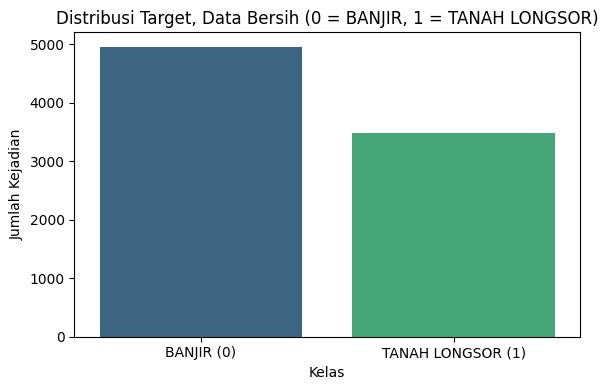

In [5]:
# Cell 5: distribusi target pada data bersih
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df_clean, hue='target', palette='viridis', legend=False)
plt.title('Distribusi Target, Data Bersih (0 = BANJIR, 1 = TANAH LONGSOR)')
plt.xticks(ticks=[0, 1], labels=['BANJIR (0)', 'TANAH LONGSOR (1)'])
plt.xlabel('Kelas')
plt.ylabel('Jumlah Kejadian')
plt.tight_layout()
plt.show()

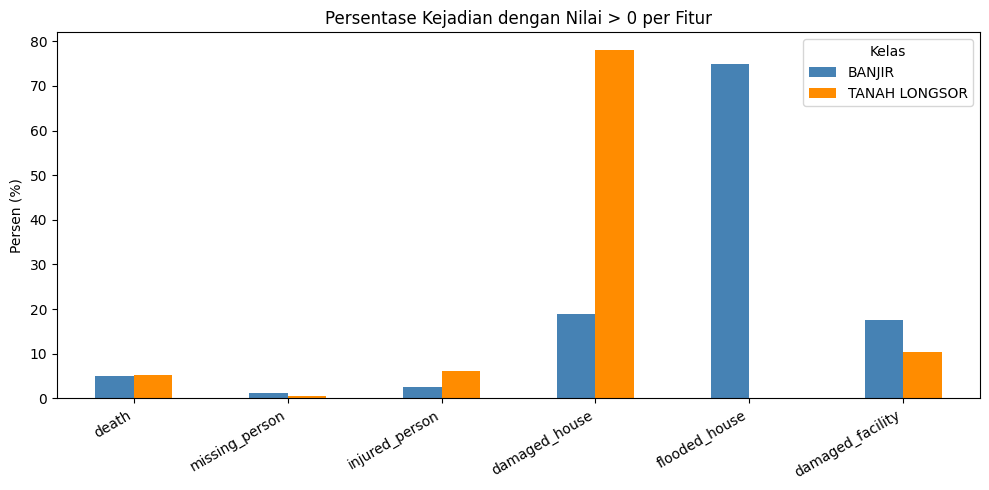

,BANJIR,TANAH LONGSOR
death,4.9,5.3
missing_person,1.1,0.5
injured_person,2.6,6.2
damaged_house,18.9,78.1
flooded_house,75.0,0.0
damaged_facility,17.5,10.4


In [6]:
# Cell 6: persentase kejadian dengan nilai > 0 per fitur, per kelas
persen = (df_clean[kolom_angka] > 0).groupby(df_clean['target']).mean() * 100
persen.index = ['BANJIR', 'TANAH LONGSOR']

ax = persen.T.plot(kind='bar', figsize=(10, 5), color=['steelblue', 'darkorange'])
ax.set_title('Persentase Kejadian dengan Nilai > 0 per Fitur')
ax.set_ylabel('Persen (%)')
ax.set_xlabel('')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Kelas')
plt.tight_layout()
plt.show()

display(persen.T.round(1))

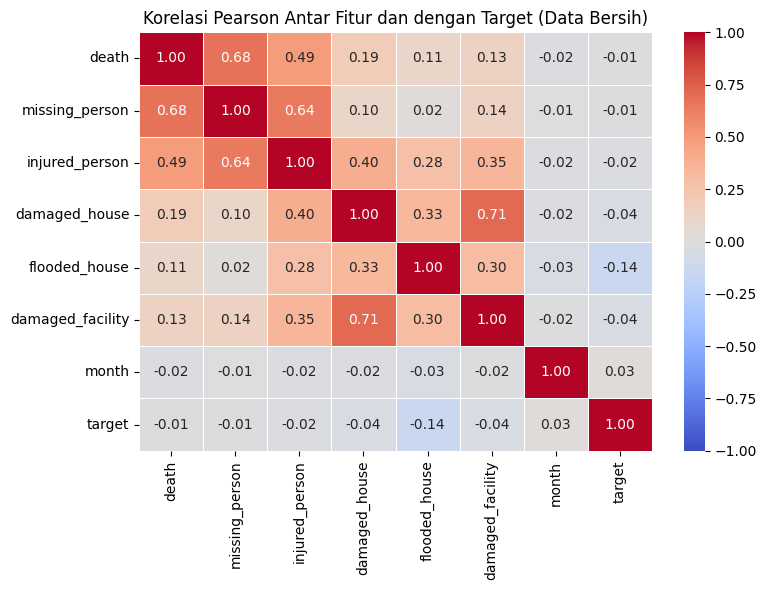

Korelasi tiap fitur dengan target (1 = longsor):
flooded_house      -0.136
damaged_house      -0.039
damaged_facility   -0.036
injured_person     -0.019
missing_person     -0.015
death              -0.012
month               0.026
Name: target, dtype: float64


In [7]:
# Cell 7: heatmap korelasi antar fitur dan dengan target (data bersih)
fitur_semua = kolom_angka + ['month']
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[fitur_semua + ['target']].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Korelasi Pearson Antar Fitur dan dengan Target (Data Bersih)')
plt.tight_layout()
plt.show()

print("Korelasi tiap fitur dengan target (1 = longsor):")
print(df_clean[fitur_semua + ['target']].corr()['target'].drop('target').sort_values().round(3))

**Insight:**
- Dua fitur membedakan kelas dengan jelas. `flooded_house` bernilai di atas 0 pada sekitar 75% banjir dan 0% longsor, sedangkan `damaged_house` jauh lebih sering pada longsor. Dugaan awal di pendahuluan terbukti.
- Tapi `flooded_house` hampir merupakan **definisi** banjir, bukan bukti independen. Karena itu ia dipisah ke **skenario B** sebagai pembanding, bukan model utama.
- Fitur korban jarang bernilai di atas 0, jadi informasinya tipis. `damaged_facility` sedikit lebih sering pada banjir.
- Korelasi dengan target: `flooded_house` paling kuat, disusul `damaged_house`. Korelasi antar fitur lemah sampai sedang, dan `month` nyaris tidak berkorelasi dengan apa pun. Korelasi nol belum membuktikan sebuah fitur tidak berguna, tapi ini petunjuk awal bahwa `month` kemungkinan lemah.

## 5. Preprocessing: Split dan Transformasi log1p

**Kenapa log1p?** Data seperti peta kota yang berisi gubuk dan gedung pencakar langit sekaligus: kebanyakan nol, sedikit nilai puluhan ribu. `log1p(x) = log(1 + x)` "menekan" jarak antar nilai agar model tidak hanya melihat yang raksasa, dan aman untuk nol.

Urutan: split dulu, transformasi kemudian. `log1p` tidak belajar apa pun dari data (tidak ada rata-rata yang dihitung), jadi tidak menimbulkan kebocoran.

In [8]:
# Cell 8: definisi dua skenario fitur, split, lalu log1p
from sklearn.model_selection import train_test_split

FITUR_A = ['death', 'missing_person', 'injured_person',
           'damaged_house', 'damaged_facility', 'month']   # tanpa flooded_house
FITUR_B = FITUR_A + ['flooded_house']                      # dengan flooded_house

X = df_clean[FITUR_B]
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

print(f"Data latih : {X_train.shape[0]} baris | Data uji : {X_test.shape[0]} baris")
print(f"Proporsi longsor - latih: {y_train.mean():.3f} | uji: {y_test.mean():.3f}")
print("Skenario A (tanpa flooded_house):", FITUR_A)
print("Skenario B (dengan flooded_house):", FITUR_B)

Data latih : 6750 baris | Data uji : 1688 baris
Proporsi longsor - latih: 0.413 | uji: 0.413
Skenario A (tanpa flooded_house): ['death', 'missing_person', 'injured_person', 'damaged_house', 'damaged_facility', 'month']
Skenario B (dengan flooded_house): ['death', 'missing_person', 'injured_person', 'damaged_house', 'damaged_facility', 'month', 'flooded_house']


## 6. Pemodelan: 2 Algoritma x 2 Skenario + Dummy

- **Skenario A (model utama):** tanpa `flooded_house`. Mengukur kemampuan prediksi dari fitur dampak yang bukan definisi kelas.
- **Skenario B (pembanding):** dengan `flooded_house`. Menunjukkan seberapa besar skor naik hanya karena satu kolom yang hampir mendefinisikan banjir.
- **Gaussian Naive Bayes** dan **Logistic Regression + StandardScaler** mengikuti pola praktik di kelas (P12).
- **Dummy classifier** selalu menebak kelas mayoritas: batas bawah yang harus dikalahkan model.

In [9]:
# Cell 9: latih 4 model (2 algoritma x 2 skenario) + dummy baseline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier

# Skenario A: tanpa flooded_house
nb_A = GaussianNB().fit(X_train_log[FITUR_A], y_train)
lr_A = make_pipeline(StandardScaler(),
                     LogisticRegression(max_iter=1000, random_state=42)).fit(X_train_log[FITUR_A], y_train)

# Skenario B: dengan flooded_house
nb_B = GaussianNB().fit(X_train_log[FITUR_B], y_train)
lr_B = make_pipeline(StandardScaler(),
                     LogisticRegression(max_iter=1000, random_state=42)).fit(X_train_log[FITUR_B], y_train)

# Dummy: selalu menebak kelas mayoritas
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_log[FITUR_A], y_train)

# Prediksi kelas dan probabilitas kelas 1 (longsor) pada data uji
pred_nb_A = nb_A.predict(X_test_log[FITUR_A])
prob_nb_A = nb_A.predict_proba(X_test_log[FITUR_A])[:, 1]
pred_lr_A = lr_A.predict(X_test_log[FITUR_A])
prob_lr_A = lr_A.predict_proba(X_test_log[FITUR_A])[:, 1]
pred_nb_B = nb_B.predict(X_test_log[FITUR_B])
prob_nb_B = nb_B.predict_proba(X_test_log[FITUR_B])[:, 1]
pred_lr_B = lr_B.predict(X_test_log[FITUR_B])
prob_lr_B = lr_B.predict_proba(X_test_log[FITUR_B])[:, 1]
pred_dummy = dummy.predict(X_test_log[FITUR_A])
prob_dummy = dummy.predict_proba(X_test_log[FITUR_A])[:, 1]

print("Selesai melatih: NB (A), LR (A), NB (B), LR (B), Dummy")
print("\nContoh 5 prediksi pertama (skenario A):")
print("Aktual :", y_test.values[:5])
print("NB (A) :", pred_nb_A[:5])
print("LR (A) :", pred_lr_A[:5])

Selesai melatih: NB (A), LR (A), NB (B), LR (B), Dummy

Contoh 5 prediksi pertama (skenario A):
Aktual : [0 0 1 1 1]
NB (A) : [1 1 1 1 1]
LR (A) : [0 0 0 0 1]


## 7. Evaluasi dan Validasi

Metrik dibaca untuk kelas **tanah longsor (1)**:
1. **Accuracy:** seberapa sering tebakan benar secara keseluruhan.
2. **Precision:** dari semua yang diprediksi longsor, berapa persen yang benar longsor.
3. **Recall:** dari semua kejadian longsor yang sebenarnya, berapa persen yang tertangkap.
4. **F1:** rata-rata harmonik precision dan recall.
5. **ROC-AUC:** kemampuan memisahkan kelas di semua ambang probabilitas. `1.0` sempurna, `0.5` sama dengan menebak acak.

Validasi: Stratified 5-fold cross validation pada data latih, supaya skor tidak bergantung pada satu pembagian data. Semua angka dibaca dari variabel hasil.

In [10]:
# Cell 10: tabel metrik semua model pada data uji
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

def baris_metrik(nama, pred, prob):
    return {
        'Model': nama,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob),
    }

tabel_uji = pd.DataFrame([
    baris_metrik('Naive Bayes (A)', pred_nb_A, prob_nb_A),
    baris_metrik('Logistic Regression (A)', pred_lr_A, prob_lr_A),
    baris_metrik('Naive Bayes (B)', pred_nb_B, prob_nb_B),
    baris_metrik('Logistic Regression (B)', pred_lr_B, prob_lr_B),
    baris_metrik('Dummy (tebak mayoritas)', pred_dummy, prob_dummy),
]).set_index('Model').round(4)

print("Metrik pada data uji (20%):")
display(tabel_uji)

Metrik pada data uji (20%):


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Naive Bayes (A),0.4805,0.4345,0.8565,0.5765,0.7581
Logistic Regression (A),0.6594,0.6918,0.3156,0.4335,0.7701
Naive Bayes (B),0.8572,0.7484,0.9857,0.8508,0.9374
Logistic Regression (B),0.8572,0.7489,0.9842,0.8506,0.9239
Dummy (tebak mayoritas),0.5871,0.0000,0.0000,0.0000,0.5000


**Insight:**
- **Skenario A lemah.** Naive Bayes jatuh di bawah dummy. Precision dan recall-nya timpang: model menebak hampir semua kejadian sebagai longsor, sehingga banyak banjir salah label. Logistic Regression sedikit di atas dummy, tapi recall longsor rendah.
- **ROC-AUC keduanya di kisaran 0,76 sampai 0,77**, jauh di atas 0,5. Artinya sinyal pembeda itu ada, tetapi ambang default 0,5 membuat accuracy Naive Bayes buruk. Masalahnya sebagian di ambang, bukan semata di kemampuan memisahkan kelas.
- **Skenario B naik drastis**, tetapi lonjakan itu berasal dari satu kolom yang hampir mendefinisikan banjir. Skor tinggi di sini bukan bukti model "pintar".

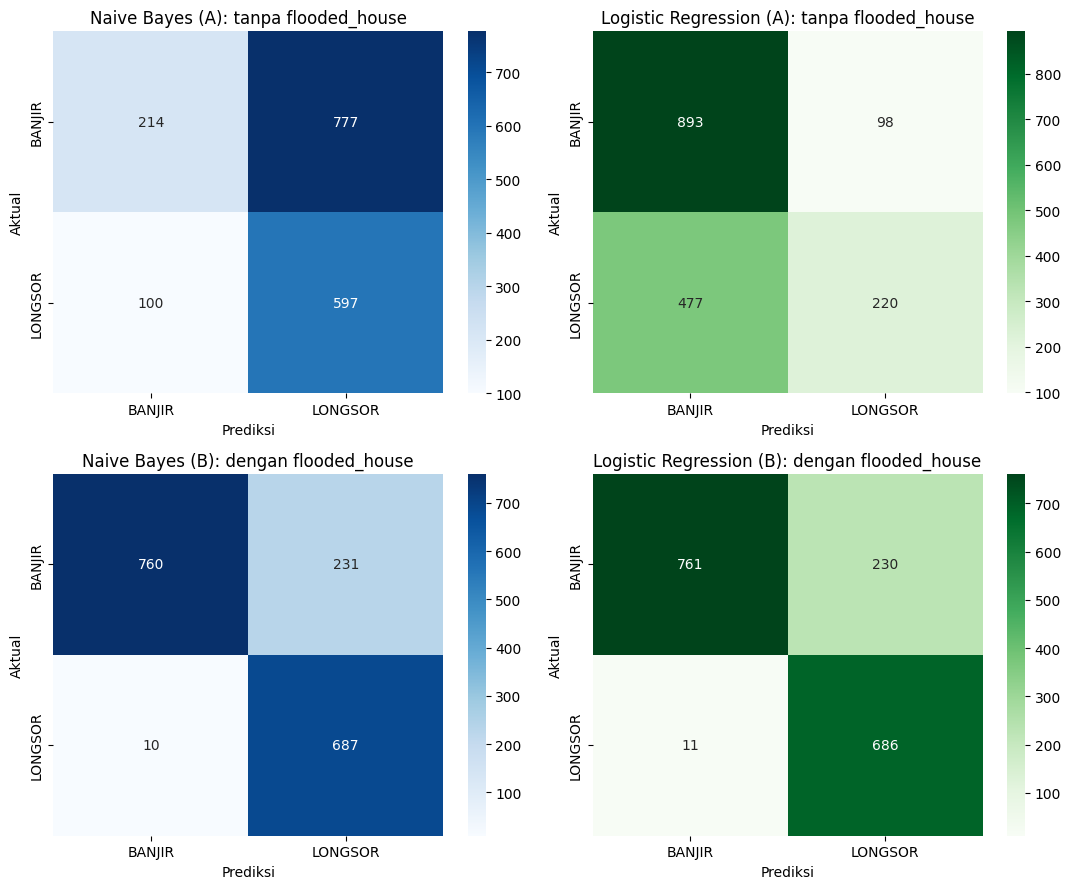

In [11]:
# Cell 11: confusion matrix keempat model
def panel_cm(ax, pred, judul, cmap):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['BANJIR', 'LONGSOR'], yticklabels=['BANJIR', 'LONGSOR'])
    ax.set_title(judul)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
panel_cm(axes[0, 0], pred_nb_A, 'Naive Bayes (A): tanpa flooded_house', 'Blues')
panel_cm(axes[0, 1], pred_lr_A, 'Logistic Regression (A): tanpa flooded_house', 'Greens')
panel_cm(axes[1, 0], pred_nb_B, 'Naive Bayes (B): dengan flooded_house', 'Blues')
panel_cm(axes[1, 1], pred_lr_B, 'Logistic Regression (B): dengan flooded_house', 'Greens')
plt.tight_layout()
plt.show()

In [12]:
# Cell 12: Stratified 5-fold cross validation (accuracy) pada data latih
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_nb_A = cross_val_score(nb_A, X_train_log[FITUR_A], y_train, cv=cv, scoring='accuracy')
cv_lr_A = cross_val_score(lr_A, X_train_log[FITUR_A], y_train, cv=cv, scoring='accuracy')
cv_nb_B = cross_val_score(nb_B, X_train_log[FITUR_B], y_train, cv=cv, scoring='accuracy')
cv_lr_B = cross_val_score(lr_B, X_train_log[FITUR_B], y_train, cv=cv, scoring='accuracy')

print("--- Cross-Validation 5-Fold (mean +/- std) ---")
print(f"NB (A): {cv_nb_A.mean():.4f} +/- {cv_nb_A.std():.4f}")
print(f"LR (A): {cv_lr_A.mean():.4f} +/- {cv_lr_A.std():.4f}")
print(f"NB (B): {cv_nb_B.mean():.4f} +/- {cv_nb_B.std():.4f}")
print(f"LR (B): {cv_lr_B.mean():.4f} +/- {cv_lr_B.std():.4f}")

--- Cross-Validation 5-Fold (mean +/- std) ---
NB (A): 0.4764 +/- 0.0049
LR (A): 0.6661 +/- 0.0079
NB (B): 0.8572 +/- 0.0069
LR (B): 0.8604 +/- 0.0069


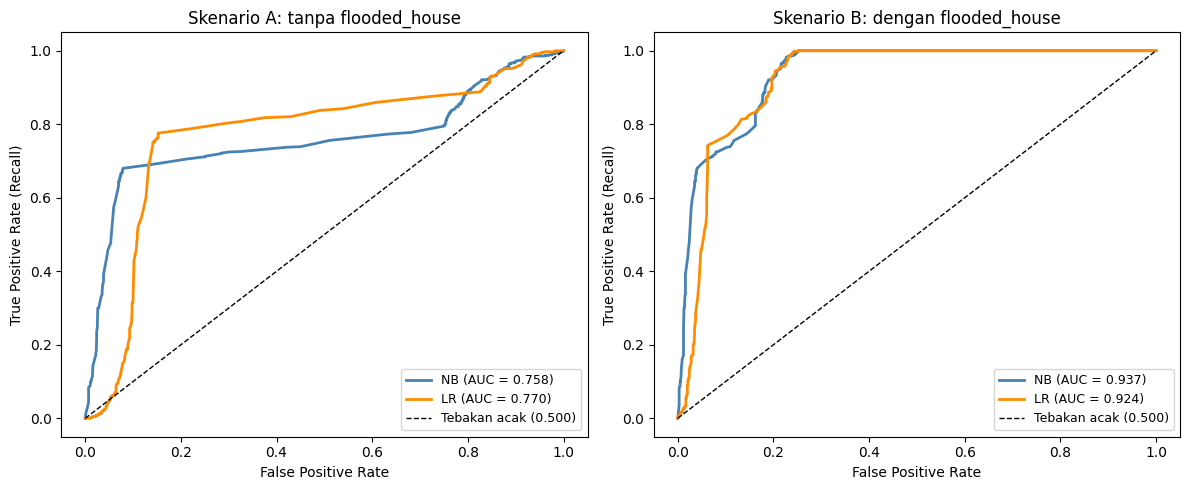

In [13]:
# Cell 13: kurva ROC kedua skenario
fpr_nb_A, tpr_nb_A, _ = roc_curve(y_test, prob_nb_A)
fpr_lr_A, tpr_lr_A, _ = roc_curve(y_test, prob_lr_A)
fpr_nb_B, tpr_nb_B, _ = roc_curve(y_test, prob_nb_B)
fpr_lr_B, tpr_lr_B, _ = roc_curve(y_test, prob_lr_B)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr_nb_A, tpr_nb_A, color='steelblue', lw=2,
             label=f'NB (AUC = {roc_auc_score(y_test, prob_nb_A):.3f})')
axes[0].plot(fpr_lr_A, tpr_lr_A, color='darkorange', lw=2,
             label=f'LR (AUC = {roc_auc_score(y_test, prob_lr_A):.3f})')
axes[0].set_title('Skenario A: tanpa flooded_house')
axes[1].plot(fpr_nb_B, tpr_nb_B, color='steelblue', lw=2,
             label=f'NB (AUC = {roc_auc_score(y_test, prob_nb_B):.3f})')
axes[1].plot(fpr_lr_B, tpr_lr_B, color='darkorange', lw=2,
             label=f'LR (AUC = {roc_auc_score(y_test, prob_lr_B):.3f})')
axes[1].set_title('Skenario B: dengan flooded_house')
for ax in axes:
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Tebakan acak (0.500)')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate (Recall)')
    ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

**Insight validasi:**
- Standar deviasi CV kecil dan rata-ratanya hampir sama dengan skor data uji tunggal. Hasil tidak bergantung pada satu kali pembagian data: skor A memang rendah, skor B memang tinggi.
- Kurva ROC skenario A berada di atas diagonal tapi jauh dari sudut kiri atas, tanda pemisahan kelas yang hanya sedang. Skenario B mendekati sudut kiri atas.
- Pada skenario B, recall longsor sangat tinggi tetapi precision lebih rendah: banjir yang tidak mencatat rumah terendam adalah sumber kesalahan utamanya.

## 8. Interpretasi Odds Ratio (Logistic Regression)

Keunggulan Logistic Regression adalah mudah diinterpretasi. **Odds Ratio = exp(koefisien)**: di atas 1 mengarah ke longsor, di bawah 1 mengarah ke banjir.

Karena fitur sudah di-log1p lalu distandardisasi, bacanya adalah *arah dan kekuatan relatif* per kenaikan 1 standar deviasi, bukan "per 1 orang" dan bukan hubungan sebab-akibat.

In [14]:
# Cell 14: odds ratio Logistic Regression kedua skenario
koef_A = lr_A.named_steps['logisticregression'].coef_[0]
koef_B = lr_B.named_steps['logisticregression'].coef_[0]

tabel_or = pd.DataFrame({
    'Odds Ratio (A)': pd.Series(np.exp(koef_A), index=FITUR_A),
    'Odds Ratio (B)': pd.Series(np.exp(koef_B), index=FITUR_B),
}).round(4)

print("Odds Ratio = exp(koefisien). > 1: mengarah ke LONGSOR, < 1: mengarah ke BANJIR")
print("(per kenaikan 1 standar deviasi pada skala log1p, fitur lain dianggap tetap)")
display(tabel_or.sort_values('Odds Ratio (A)', ascending=False))

Odds Ratio = exp(koefisien). > 1: mengarah ke LONGSOR, < 1: mengarah ke BANJIR
(per kenaikan 1 standar deviasi pada skala log1p, fitur lain dianggap tetap)


,Odds Ratio (A),Odds Ratio (B)
damaged_house,2.0576,1.2659
injured_person,1.1460,1.2253
month,1.0180,0.9623
death,0.9527,0.8836
missing_person,0.8409,0.9204
damaged_facility,0.4881,0.5328
flooded_house,NaN,0.0004


**Insight:**
- `damaged_house` punya OR sekitar 2: kenaikan 1 standar deviasi pada skala log1p rumah rusak menaikkan odds longsor sekitar dua kali lipat. Ini konsisten dengan EDA.
- `damaged_facility` punya OR di bawah 1, artinya fasilitas rusak lebih mengarah ke banjir.
- `death` dan `missing_person` OR-nya mendekati 1, jadi pengaruhnya kecil. Data ini **tidak mendukung** anggapan bahwa longsor lebih mematikan.
- Pada skenario B, `flooded_house` punya koefisien sangat negatif (OR mendekati 0) dan mendominasi model. OR `damaged_house` ikut turun karena sebagian daya pembeda sudah diambil alih kolom itu.
- Semua angka ini menunjukkan asosiasi pada data pencatatan, bukan sebab-akibat.

## 9. Simpan Data Bersih

Data bersih disimpan sebagai lampiran tugas (untuk diunggah ke GitHub sebagai "excel data"). File ini adalah **hasil** notebook, bukan input.

In [15]:
# Cell 15: simpan data bersih sebagai lampiran
df_clean.to_csv('../data_processed/data_bersih_banjir_longsor.csv', index=False)
df_clean.to_excel('../data_processed/data_bersih_banjir_longsor.xlsx', index=False)
print("Tersimpan: ../data_processed/data_bersih_banjir_longsor.csv dan .xlsx")
print("Isi:", df_clean.shape[0], "baris,", df_clean.shape[1], "kolom")

Tersimpan: data_bersih_banjir_longsor.csv dan .xlsx
Isi: 8438 baris, 14 kolom


## 10. Interpretasi Hasil dan Kesimpulan

In [16]:
# Cell 16: ringkasan akhir, semua angka dibaca dari variabel hasil
print("=" * 64)
print("RINGKASAN AKHIR (data bersih)")
print("=" * 64)
print(f"Data bersih: {len(df_clean)} baris (dari {len(df_filtered)} baris hasil filter kelas)")
print(f"Dummy baseline accuracy : {tabel_uji.loc['Dummy (tebak mayoritas)', 'Accuracy']:.4f}")
print("-" * 64)
for nama in ['Naive Bayes (A)', 'Logistic Regression (A)', 'Naive Bayes (B)', 'Logistic Regression (B)']:
    acc = tabel_uji.loc[nama, 'Accuracy']
    auc = tabel_uji.loc[nama, 'ROC-AUC']
    print(f"{nama:26s} accuracy = {acc:.4f} | ROC-AUC = {auc:.4f}")
print("-" * 64)
print("Catatan: skenario B tinggi terutama karena flooded_house,")
print("kolom yang hampir merupakan definisi banjir. Kemampuan prediksi")
print("dari fitur dampak lain saja terlihat di skenario A.")

RINGKASAN AKHIR (data bersih)
Data bersih: 8438 baris (dari 14190 baris hasil filter kelas)
Dummy baseline accuracy : 0.5871
----------------------------------------------------------------
Naive Bayes (A)            accuracy = 0.4805 | ROC-AUC = 0.7581
Logistic Regression (A)    accuracy = 0.6594 | ROC-AUC = 0.7701
Naive Bayes (B)            accuracy = 0.8572 | ROC-AUC = 0.9374
Logistic Regression (B)    accuracy = 0.8572 | ROC-AUC = 0.9239
----------------------------------------------------------------
Catatan: skenario B tinggi terutama karena flooded_house,
kolom yang hampir merupakan definisi banjir. Kemampuan prediksi
dari fitur dampak lain saja terlihat di skenario A.


### 10.1 Menjawab Pertanyaan Awal
Catatan dampak suatu kejadian **bisa** membedakan banjir dari tanah longsor, tetapi seberapa baik sangat bergantung pada satu kolom.

- **Tanpa `flooded_house` (skenario A):** sinyal ada tetapi lemah. ROC-AUC sekitar 0,76 sampai 0,77 dan accuracy terbaik sekitar 0,66 (Logistic Regression) dibanding baseline 0,59. Pembeda utamanya `damaged_house`, dengan bantuan kecil dari `damaged_facility`.
- **Dengan `flooded_house` (skenario B):** accuracy sekitar 0,86 dan ROC-AUC 0,92 sampai 0,94. Namun aturan satu baris "rumah terendam lebih dari 0 berarti banjir" saja sudah mendekati skor itu, jadi angka ini bukan bukti model yang benar-benar memahami pola.

Dugaan awal di pendahuluan terbukti: banjir ditandai rumah terendam, longsor ditandai rumah rusak.

### 10.2 Perbandingan Kedua Model
- **Skenario A:** Logistic Regression lebih baik. Naive Bayes menebak hampir semua kejadian sebagai longsor pada ambang 0,5, sehingga accuracy-nya jatuh di bawah dummy meski AUC-nya mirip LR.
- **Skenario B:** keduanya praktis setara, dengan NB sedikit unggul pada ROC-AUC.
- Tidak ada pemenang mutlak. Logistic Regression lebih kami rekomendasikan sebagai model utama karena konsisten di kedua skenario dan mudah diinterpretasi lewat odds ratio.

### 10.3 Temuan Kualitas Data yang Menentukan Hasil
Nilai kosong pada kolom korban dan `flooded_house` ternyata diisi dengan rata-rata per jenis bencana oleh pembuat data. Karena tiap kelas punya satu nilai pecahan khas, nilai itu membocorkan label (data leakage). Membulatkan tidak menghilangkan jejaknya, jadi baris tersebut dibuang. Keputusan ini menentukan seluruh hasil di atas: tanpa pemeriksaan ini, skor model akan tampak jauh lebih tinggi daripada kemampuan sebenarnya.

### 10.4 Hal yang Tidak Didukung Data
- Perbedaan korban jiwa antar kedua kelas kecil, sehingga data ini tidak mendukung anggapan bahwa longsor lebih mematikan.
- `month` hampir tidak berkorelasi dengan target dan koefisiennya mendekati nol, jadi faktor bulan bukan pembeda utama di dataset ini.
- Rasio kelas 60:40 tidak memerlukan teknik resampling.

### 10.5 Keterbatasan
1. Hanya sekitar 60% baris yang dipakai. Tahun 2019, 2022, dan 2023 hampir habis, sehingga cakupan waktu tidak merata dan kesimpulan tidak berlaku untuk periode itu. Penyebab pengisian rata-rata di sumber data belum diketahui.
2. Fitur dampak sebagian besar bernilai nol, dan tidak ada fitur penyebab (curah hujan, topografi). Tanpa `flooded_house`, kemampuan prediksi terbatas.
3. Fitur lokasi (`province`, `city`) dan teks `cause` belum dimanfaatkan, padahal EDA awal menunjukkan pola wilayah yang menarik.
4. Ambang prediksi masih default 0,5 dan belum disetel. Padahal AUC Naive Bayes skenario A jauh di atas 0,5, jadi sebagian masalah accuracy-nya ada di ambang.
5. Validasi berbasis waktu (latih tahun lama, uji tahun baru) belum dilakukan.
6. Duplikat persis dibuang, padahal sebagian mungkin kejadian terpisah di wilayah yang sama.
7. Hasil menunjukkan asosiasi, bukan sebab-akibat.

### 10.6 Saran Lanjutan
- Konfirmasi ke pemilik dataset bagaimana nilai kosong diisi, dan apakah catatan 2019, 2022, 2023 memang tidak tersedia.
- Untuk prediksi jenis bencana yang sesungguhnya, tambahkan fitur **sebelum** kejadian: curah hujan, topografi atau kelerengan, dan data geospasial.
- Coba fitur biner (ada atau tidak ada kerusakan), penyetelan ambang probabilitas, encoding provinsi, dan model non-linear seperti Random Forest.

## 11. Pemeriksaan Tambahan: Kualitas Data per Tahun dan Uji Lintas Tahun

Bagian ini menambahkan dua pemeriksaan yang belum ada sebelumnya:
1. **Kualitas data per tahun.** Seberapa besar porsi baris per tahun yang berisi nilai isian rata-rata, sehingga tidak mencerminkan catatan kejadian asli.
2. **Uji lintas tahun.** Model dilatih di tahun tertentu dan diuji di tahun yang belum pernah dilihat, untuk melihat apakah pola bertahan ke waktu lain.

Pemeriksaan ini menggunakan `random_state=42` yang sama dengan bagian lain.

Porsi baris berisi nilai isian rata-rata per tahun (setelah duplikat dibuang):


,total_baris,berisi_isian,persen_isian
date,,,
2018,1517,0,0.0
2019,1505,1446,96.1
2020,2731,0,0.0
2021,3546,2,0.1
2022,2255,2254,100.0
2023,1872,1871,99.9
2024,620,35,5.6


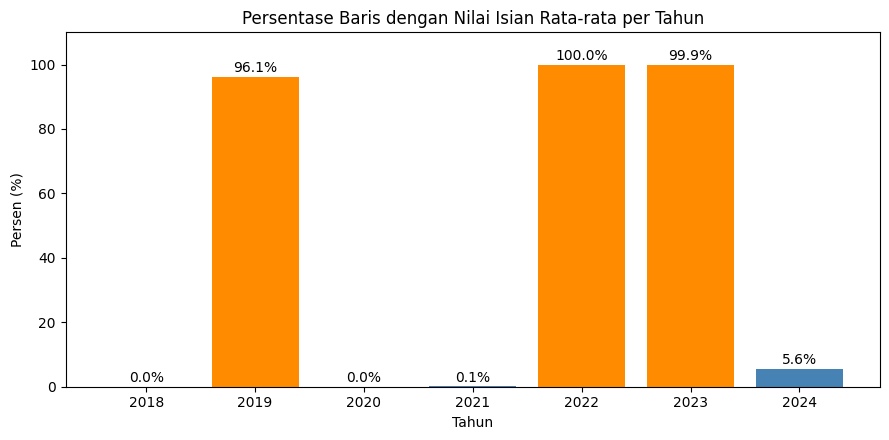

In [17]:
# Cell 17: kualitas data per tahun (porsi baris berisi nilai isian rata-rata)
kolom_isian = ['death', 'missing_person', 'injured_person', 'damaged_house', 'flooded_house', 'damaged_facility']
f_all = df_filtered.drop_duplicates().copy()
baris_isian = (f_all[kolom_isian] % 1 != 0).any(axis=1)

tbl_tahun = pd.DataFrame({
    'total_baris': f_all.date.dt.year.value_counts(),
    'berisi_isian': baris_isian.groupby(f_all.date.dt.year).sum(),
}).sort_index()
tbl_tahun['persen_isian'] = (tbl_tahun.berisi_isian / tbl_tahun.total_baris * 100).round(1)
print("Porsi baris berisi nilai isian rata-rata per tahun (setelah duplikat dibuang):")
display(tbl_tahun)

plt.figure(figsize=(9, 4.5))
warna = ['darkorange' if p > 50 else 'steelblue' for p in tbl_tahun.persen_isian]
plt.bar(tbl_tahun.index.astype(str), tbl_tahun.persen_isian, color=warna)
for x, y in enumerate(tbl_tahun.persen_isian):
    plt.text(x, y + 1.5, f'{y:.1f}%', ha='center')
plt.title('Persentase Baris dengan Nilai Isian Rata-rata per Tahun')
plt.ylabel('Persen (%)')
plt.xlabel('Tahun')
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

**Insight:**
- Tahun 2019, 2022, dan 2023 nyaris seluruhnya berisi nilai isian rata-rata. Tahun 2022 dan 2023 bahkan 100% dan 99,9%.
- Sisa baris bersih di tahun-tahun itu hanya 59 (2019), 1 (2022), dan 1 (2023). Tahun-tahun itu praktis tidak ikut dilatih maupun diuji.
- Pola ini terkonsentrasi per tahun, bukan acak. Kemungkinan ada satu blok data dari sumber yang diisi dengan cara berbeda. Konfirmasi ke pemilik dataset diperlukan.

In [18]:
# Cell 18: pemeriksaan kualitas lain pada data mentah + korelasi Spearman vs Pearson
print("Duplikat pada data mentah (sebelum filter kelas):", df.duplicated().sum())
print("\nBaris dengan nilai kosong pada data mentah, per jenis bencana:")
print(df[df[['missing_person', 'flooded_house', 'death']].isnull().any(axis=1)]['disaster_type'].value_counts())

m_city = df.groupby('city')['city_id'].nunique()
print(f"\nKota dengan lebih dari satu city_id: {(m_city > 1).sum()} dari {len(m_city)} kota")
print(f"Porsi cause bernilai 'Tidak diketahui': {(df['cause'] == 'Tidak diketahui').mean():.1%}")

fitur_k = kolom_angka + ['month']
korelasi = pd.DataFrame({
    'Pearson': df_clean[fitur_k + ['target']].corr()['target'].drop('target'),
    'Spearman': df_clean[fitur_k + ['target']].corr(method='spearman')['target'].drop('target'),
}).round(3)
print("\nKorelasi tiap fitur dengan target (1 = longsor), data bersih:")
display(korelasi.sort_values('Spearman'))
print("\nCatatan: Pearson sensitif terhadap outlier (damaged_house maksimal 19.812 di banjir).")
print("Spearman mengurutkan nilai dulu, sehingga lebih tepat untuk data dengan nilai ekstrem.")

Duplikat pada data mentah (sebelum filter kelas): 329

Baris dengan nilai kosong pada data mentah, per jenis bencana:
disaster_type
PUTING BELIUNG        1113
LETUSAN GUNUNG API       1
Name: count, dtype: int64

Kota dengan lebih dari satu city_id: 150 dari 538 kota
Porsi cause bernilai 'Tidak diketahui': 39.7%

Korelasi tiap fitur dengan target (1 = longsor), data bersih:


,Pearson,Spearman
flooded_house,-0.136,-0.704
damaged_facility,-0.036,-0.110
missing_person,-0.015,-0.030
death,-0.012,0.008
month,0.026,0.018
injured_person,-0.019,0.090
damaged_house,-0.039,0.500



Catatan: Pearson sensitif terhadap outlier (damaged_house maksimal 19.812 di banjir).
Spearman mengurutkan nilai dulu, sehingga lebih tepat untuk data dengan nilai ekstrem.


**Insight:**
- Pearson dan Spearman memberi arah yang berbeda untuk `damaged_house`. Pearson negatif kecil karena outlier, sedangkan Spearman positif sedang. Arah Spearman sejalan dengan odds ratio di Bagian 8.
- `flooded_house` kuat di kedua ukuran, dengan arah negatif (mengarah ke banjir).
- `month` tetap hampir nol di kedua ukuran.

Data latih (2018, 2020, 2021): 7792 baris
Data uji (2024)              : 585 baris, proporsi longsor 0.115
Dummy baseline accuracy      : 0.8855



,Model,Accuracy,ROC-AUC
0,Naive Bayes (A),0.1778,0.4023
1,Logistic Regression (A),0.8769,0.7656
2,Naive Bayes (B),0.9949,1.0000
3,Logistic Regression (B),0.9949,1.0000


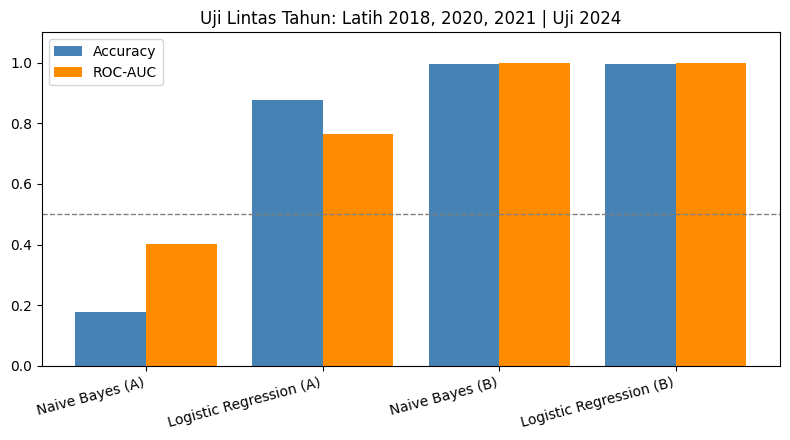

In [19]:
# Cell 19: uji lintas tahun (latih 2018, 2020, 2021; uji 2024)
tr_mask = df_clean['date'].dt.year.isin([2018, 2020, 2021])
te_mask = df_clean['date'].dt.year == 2024

X_tr_t = np.log1p(df_clean.loc[tr_mask, FITUR_B]); y_tr_t = df_clean.loc[tr_mask, 'target']
X_te_t = np.log1p(df_clean.loc[te_mask, FITUR_B]); y_te_t = df_clean.loc[te_mask, 'target']

print(f"Data latih (2018, 2020, 2021): {tr_mask.sum()} baris")
print(f"Data uji (2024)              : {te_mask.sum()} baris, proporsi longsor {y_te_t.mean():.3f}")
print(f"Dummy baseline accuracy      : {1 - y_te_t.mean():.4f}\n")

hasil_t = []
for nama, F in [('A', FITUR_A), ('B', FITUR_B)]:
    modelnya = [
        ('Naive Bayes', GaussianNB()),
        ('Logistic Regression', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))),
    ]
    for nm, mdl in modelnya:
        mdl.fit(X_tr_t[F], y_tr_t)
        pred = mdl.predict(X_te_t[F])
        prob = mdl.predict_proba(X_te_t[F])[:, 1]
        hasil_t.append({'Model': f'{nm} ({nama})',
                        'Accuracy': accuracy_score(y_te_t, pred),
                        'ROC-AUC': roc_auc_score(y_te_t, prob)})
hasil_t = pd.DataFrame(hasil_t).round(4)
display(hasil_t)

plt.figure(figsize=(8, 4.5))
x = np.arange(len(hasil_t))
plt.bar(x - 0.2, hasil_t['Accuracy'], 0.4, label='Accuracy', color='steelblue')
plt.bar(x + 0.2, hasil_t['ROC-AUC'], 0.4, label='ROC-AUC', color='darkorange')
plt.xticks(x, hasil_t['Model'], rotation=15, ha='right')
plt.ylim(0, 1.1)
plt.axhline(0.5, color='grey', ls='--', lw=1)
plt.title('Uji Lintas Tahun: Latih 2018, 2020, 2021 | Uji 2024')
plt.legend()
plt.tight_layout()
plt.show()

**Insight:**
- **Logistic Regression skenario A** tetap sekitar 0,77 ROC-AUC di tahun baru. Sinyal dampak bertahan ke waktu yang berbeda.
- **Naive Bayes skenario A** turun ke bawah 0,5 di tahun baru. Model ini tidak stabil ketika data berpindah tahun.
- **Skenario B** mendapat angka sempurna. Ini karena `flooded_house` hampir sama dengan label, bukan karena model benar-benar memahami pola.
- Accuracy Logistic Regression A di bawah dummy. Tahun 2024 didominasi banjir (hanya sekitar 11,5% longsor), jadi ROC-AUC lebih tepat untuk dibaca.
- Uji ini memakai data Januari sampai Mei 2024 saja, sehingga angkanya indikasi awal, bukan kepastian.